# 06 - Saved Model Verification

This notebook checks the saved local model before using it in the application. It evaluates the model on the same untouched, stratified 20% test partition used by the hybrid-model workflow. It does **not** retrain, calibrate, tune, or change the model or test data.

The fraud label is `t` (mapped to 1); the legitimate label is `f` (mapped to 0). We rebuild the feature rows from the raw CSV and verify their order against the processed CSV before recreating the split.

## 1. Load and inspect the saved model

In [11]:
from pathlib import Path
import json
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_PATH = PROJECT_DIR / "models" / "fake_job_detector.joblib"
METADATA_PATH = PROJECT_DIR / "models" / "fake_job_detector_metadata.json"
PROCESSED_PATH = PROJECT_DIR / "data" / "processed" / "processed_job_postings.csv"
RAW_PATH = PROJECT_DIR / "data" / "raw" / "DataSet.csv"
REPORT_PATH = PROJECT_DIR / "report" / "model_verification_report.md"

for path in [MODEL_PATH, METADATA_PATH, PROCESSED_PATH, RAW_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Required verification input not found: {path}")

model = joblib.load(MODEL_PATH)
with METADATA_PATH.open(encoding="utf-8") as file:
    model_metadata = json.load(file)

print("Model loaded successfully:", MODEL_PATH)
print("Loaded object type:", type(model))
print("Has predict:", callable(getattr(model, "predict", None)))
print("Has predict_proba:", callable(getattr(model, "predict_proba", None)))
print("Model classes:", model.classes_)
print("Calibration method:", model_metadata["calibration"])

# The saved object is a probability-calibrated classifier around the complete pipeline.
if not hasattr(model, "calibrated_classifiers_") or not model.calibrated_classifiers_:
    raise TypeError("Expected a fitted calibrated estimator wrapping the full preprocessing pipeline.")
base_pipeline = model.calibrated_classifiers_[0].estimator
if not hasattr(base_pipeline, "named_steps") or not hasattr(base_pipeline, "steps"):
    raise TypeError("The calibrated estimator does not contain a complete sklearn Pipeline.")

print("\nComplete preprocessing/model pipeline:")
for step_name, step in base_pipeline.steps:
    print(f"- {step_name}: {type(step).__name__}")

classifier = base_pipeline.named_steps["classifier"]
print("\nClassifier:", type(classifier).__name__)
print("Classifier main parameters:")
for parameter, value in classifier.get_params(deep=False).items():
    print(f"  {parameter}: {value}")

print("\nPreprocessing details:")
preprocessor = base_pipeline.named_steps.get("preprocessor")
if preprocessor is not None and hasattr(preprocessor, "transformers_"):
    for name, transformer, columns in preprocessor.transformers_:
        print(f"- {name}: columns={columns}")
        if hasattr(transformer, "steps"):
            for substep_name, substep in transformer.steps:
                print(f"    {substep_name}: {type(substep).__name__}")
                if hasattr(substep, "get_params") and substep_name in {"tfidf", "onehot", "scaler"}:
                    print(f"      params: {substep.get_params(deep=False)}")

Model loaded successfully: <PROJECT_ROOT>\models\fake_job_detector.joblib
Loaded object type: <class 'sklearn.calibration.CalibratedClassifierCV'>
Has predict: True
Has predict_proba: True
Model classes: [0 1]
Calibration method: sigmoid (Platt scaling)

Complete preprocessing/model pipeline:
- preprocessor: ColumnTransformer
- classifier: LinearSVC

Classifier: LinearSVC
Classifier main parameters:
  C: 1.0
  class_weight: balanced
  dual: auto
  fit_intercept: True
  intercept_scaling: 1
  loss: squared_hinge
  max_iter: 50000
  multi_class: ovr
  penalty: l2
  random_state: 42
  tol: 0.01
  verbose: 0

Preprocessing details:
- text: columns=combined_text
- categorical: columns=['location', 'department', 'salary_range', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'telecommuting', 'has_company_logo', 'has_questions']
    imputer: SimpleImputer
    onehot: OneHotEncoder
      params: {'categories': 'auto', 'drop': None, 'dtype': <class 'numpy

## 2. Recreate the held-out test partition

The hybrid workflow used `test_size=0.2`, `stratify=y`, and `random_state=42`. Recreating that split gives the same test rows, assuming the source and processed files are unchanged. We first verify exact row alignment to avoid silently evaluating the wrong postings.

In [12]:
numeric_features = model_metadata["numeric_features"]
categorical_features = model_metadata["categorical_features"]
text_feature = model_metadata["text_feature"]

processed = pd.read_csv(
    PROCESSED_PATH,
    usecols=[text_feature, "fraudulent", *numeric_features],
    low_memory=False,
)
raw = pd.read_csv(RAW_PATH, low_memory=False).drop_duplicates().copy()
if len(raw) != len(processed):
    raise ValueError(f"Row counts differ after exact deduplication: raw={len(raw)}, processed={len(processed)}")

raw_text_columns = [
    column for column in ["title", "company_profile", "description", "requirements", "benefits"]
    if column in raw.columns
]
if not raw_text_columns:
    raise ValueError("No expected raw text columns were found.")

raw_selected = raw[[*categorical_features, "fraudulent", *raw_text_columns]].copy()
for column in raw_selected.select_dtypes(include=["object", "string"]).columns:
    raw_selected[column] = raw_selected[column].replace(r"^\s*$", pd.NA, regex=True)

raw_combined = raw_selected[raw_text_columns].fillna("").astype(str).agg(" ".join, axis=1)

def clean_text(value):
    text = "" if pd.isna(value) else str(value)
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\b(?:https?://|www\.)\S+", " URL ", text, flags=re.IGNORECASE)
    text = re.sub(r"\b[\w.+%-]+@[\w.-]+\.[a-z]{2,}\b", " EMAIL ", text, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", text).strip()

rebuilt_text = raw_combined.map(clean_text).to_numpy()
processed_text = processed[text_feature].fillna("").astype(str).to_numpy()
if not np.array_equal(rebuilt_text, processed_text):
    raise ValueError("Rebuilt text does not match processed text row by row; stop rather than evaluate misaligned data.")

raw_labels = raw_selected["fraudulent"].astype(str).str.strip().str.lower().to_numpy()
processed_labels = processed["fraudulent"].astype(str).str.strip().str.lower().to_numpy()
if not np.array_equal(raw_labels, processed_labels):
    raise ValueError("Raw and processed labels do not match row by row.")
if set(processed_labels) != {"f", "t"}:
    raise ValueError(f"Unexpected target labels: {sorted(set(processed_labels))}")

X = processed[[text_feature, *numeric_features]].copy()
for column in categorical_features:
    X[column] = raw_selected[column].reset_index(drop=True)
X = X[[text_feature, *categorical_features, *numeric_features]]
y = pd.Series(processed_labels, index=X.index).map({"f": 0, "t": 1}).astype("int8")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
test_raw = raw_selected.reset_index(drop=True).iloc[X_test.index].copy()

print(f"Row alignment verified. Deduplicated rows: {len(X):,}")
print(f"Training rows (not re-fit here): {len(X_train):,}")
print(f"Held-out test rows: {len(X_test):,}")
print("Test labels (0=legitimate, 1=fraud):", y_test.value_counts().sort_index().to_dict())
print("The model is not fitted or calibrated in this notebook.")

Row alignment verified. Deduplicated rows: 17,645
Training rows (not re-fit here): 14,116
Held-out test rows: 3,529
Test labels (0=legitimate, 1=fraud): {0: 3357, 1: 172}
The model is not fitted or calibrated in this notebook.


## 3. Evaluate on the untouched test set

The model and preprocessing pipeline are only used to predict. Fraud is the positive class (`1`). PR-AUC is reported as average precision, which emphasizes performance on the minority fraud class.

In [13]:
class_order = [0, 1]
target_names = ["Legitimate (f)", "Fraudulent (t)"]
y_pred = model.predict(X_test).astype(int)
probability_columns = list(model.classes_).index(1)
y_probability = model.predict_proba(X_test)[:, probability_columns]

report_text = classification_report(
    y_test, y_pred, labels=class_order, target_names=target_names, zero_division=0
)
matrix = confusion_matrix(y_test, y_pred, labels=class_order)
fraud_precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
fraud_recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
fraud_f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)
pr_auc = average_precision_score(y_test, y_probability)

print("Classification report:")
print(report_text)
print("Confusion matrix (rows=actual, columns=predicted; legitimate then fraud):")
print(matrix)
print("Fraud-class precision:", f"{fraud_precision:.4f}")
print("Fraud-class recall:", f"{fraud_recall:.4f}")
print("Fraud-class F1-score:", f"{fraud_f1:.4f}")
print("ROC-AUC:", f"{roc_auc:.4f}")
print("PR-AUC (average precision):", f"{pr_auc:.4f}")

Classification report:
                precision    recall  f1-score   support

Legitimate (f)       0.99      0.99      0.99      3357
Fraudulent (t)       0.87      0.79      0.83       172

      accuracy                           0.98      3529
     macro avg       0.93      0.89      0.91      3529
  weighted avg       0.98      0.98      0.98      3529

Confusion matrix (rows=actual, columns=predicted; legitimate then fraud):
[[3336   21]
 [  36  136]]
Fraud-class precision: 0.8662
Fraud-class recall: 0.7907
Fraud-class F1-score: 0.8267
ROC-AUC: 0.9884
PR-AUC (average precision): 0.8981


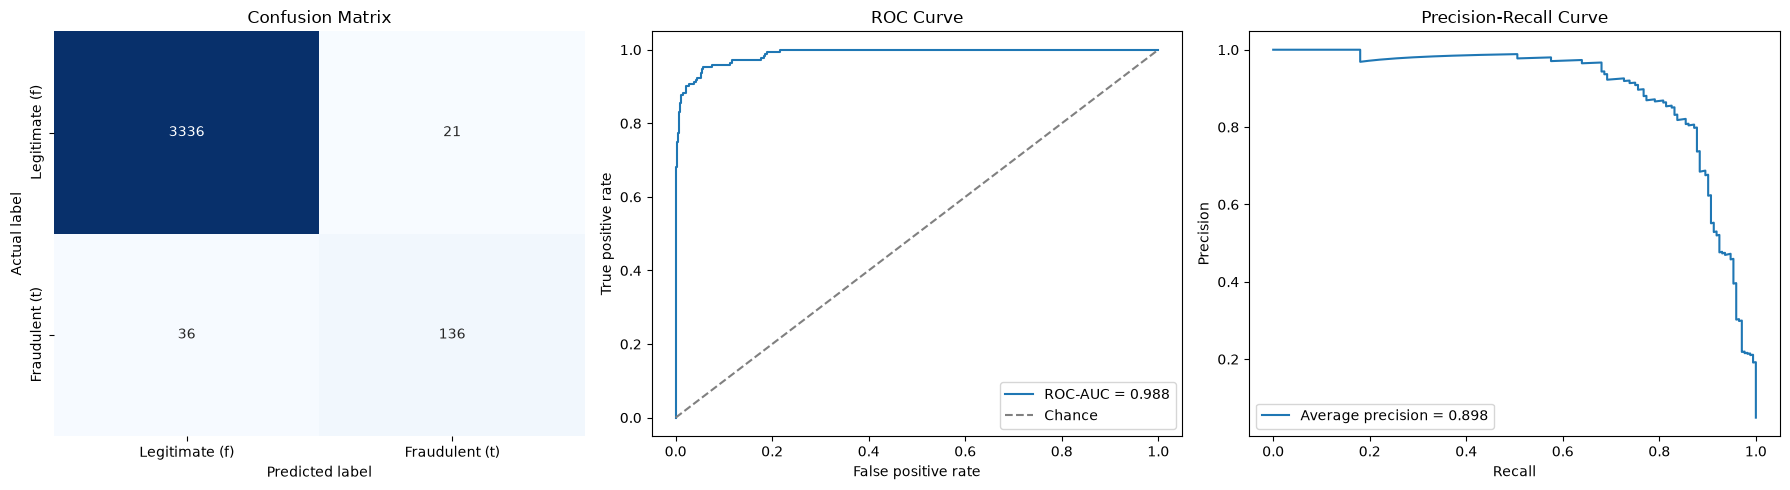

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=target_names, yticklabels=target_names, ax=axes[0]
)
axes[0].set(title="Confusion Matrix", xlabel="Predicted label", ylabel="Actual label")

fpr, tpr, _ = roc_curve(y_test, y_probability)
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[1].set(title="ROC Curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend()

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_probability)
axes[2].plot(recall_curve, precision_curve, label=f"Average precision = {pr_auc:.3f}")
axes[2].set(title="Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
axes[2].legend()

plt.tight_layout()
plt.show()

## 4. Inspect five real and five fake test postings

These examples are selected only from the held-out test rows. The probability shown is the model's calibrated estimate for the fraudulent class.

In [15]:
example_rows = []
for actual_label, label_name in [(0, "Legitimate (f)"), (1, "Fraudulent (t)")]:
    matching_indices = y_test.index[y_test == actual_label][:5]
    if len(matching_indices) < 5:
        raise ValueError(f"Only {len(matching_indices)} test examples found for {label_name}.")
    for row_index in matching_indices:
        position = X_test.index.get_loc(row_index)
        raw_row = test_raw.loc[row_index]
        example_rows.append({
            "title": raw_row.get("title", ""),
            "actual_label": label_name,
            "predicted_label": "Fraudulent (t)" if y_pred[position] == 1 else "Legitimate (f)",
            "fraud_probability": float(y_probability[position]),
        })

examples_df = pd.DataFrame(example_rows)
display(examples_df.style.format({"fraud_probability": "{:.2%}"}))

,title,actual_label,predicted_label,fraud_probability
0,Sales Representative,Legitimate (f),Legitimate (f),0.95%
1,File Clerk,Legitimate (f),Legitimate (f),0.22%
2,"Director, Information Security",Legitimate (f),Legitimate (f),2.76%
3,English Teacher Overseas,Legitimate (f),Legitimate (f),0.05%
4,Sales Manager Netigate Sverige,Legitimate (f),Legitimate (f),0.02%
5,Urgent Requirement : Senior Exchange & Active Directory Systems Administrator for Qatar.,Fraudulent (t),Fraudulent (t),67.74%
6,"LEAN Program Manager, Carol Stream, IL",Fraudulent (t),Legitimate (f),5.31%
7,Customer Service Representative,Fraudulent (t),Fraudulent (t),98.40%
8,Junior Project Manager,Fraudulent (t),Legitimate (f),0.77%
9,Finance Assistant,Fraudulent (t),Fraudulent (t),82.47%


## 5. Save the verification report

The report records the model structure, held-out test metrics, class-level results, and deployment considerations. The plots remain visible in the notebook.

In [16]:
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

steps_markdown = "\n".join(
    f"- `{step_name}`: `{type(step).__name__}`" for step_name, step in base_pipeline.steps
)
classifier_parameters = classifier.get_params(deep=False)
main_parameters = {
    key: classifier_parameters[key]
    for key in ["C", "class_weight", "max_iter", "tol", "random_state"]
    if key in classifier_parameters
}
confusion_markdown = (
    "| Actual class | Predicted legitimate | Predicted fraudulent |\n"
    "|---|---:|---:|\n"
    f"| Legitimate | {matrix[0, 0]} | {matrix[0, 1]} |\n"
    f"| Fraudulent | {matrix[1, 0]} | {matrix[1, 1]} |"
)
example_lines = [
    "| Title | Actual label | Predicted label | Fraud probability |",
    "|---|---|---|---:|",
]
for row in examples_df.itertuples(index=False):
    safe_title = str(row.title).replace("|", "\\|").replace("\n", " ")
    example_lines.append(
        f"| {safe_title} | {row.actual_label} | {row.predicted_label} | {row.fraud_probability:.2%} |"
    )
examples_markdown = "\n".join(example_lines)

deployment_ready = (
    callable(getattr(model, "predict_proba", None))
    and len(X_test) > 0
    and len(examples_df) == 10
)
readiness_text = (
    "The artifact loaded, includes the complete preprocessing pipeline, and returns calibrated fraud probabilities. "
    "It is technically ready for a local application smoke test, provided the app constructs the same input schema and feature definitions. "
    "Predictions are risk estimates, not proof that a posting is fraudulent; retain safety guidance and human verification."
    if deployment_ready
    else "A required verification check failed. Do not deploy until the saved artifact or its input schema is corrected and this notebook passes."
)

report = f"""# Saved Model Verification Report

## Verification outcome

- Model file: `{MODEL_PATH.relative_to(PROJECT_DIR)}`
- Load successful: yes
- Saved object: `{type(model).__name__}`
- Complete pipeline: yes; calibrated wrapper contains a fitted preprocessing-and-classification pipeline
- Classifier: `{type(classifier).__name__}`
- Classifier parameters: `{main_parameters}`
- Calibration: `{model_metadata['calibration']}` using {model_metadata['calibration_cv']}-fold CV on the training partition
- Test split: stratified 80/20, `random_state=42`, reconstructed to match the hybrid workflow
- Test rows: {len(X_test):,}; exact text and target row alignment checks passed
- Test rows used for training/calibration/feature selection: no

## Preprocessing pipeline

{steps_markdown}

The full transformers are part of the serialized model, so application inputs go through the same fitted text, categorical, and numerical processing used by the classifier.

## Held-out test metrics

- Fraud precision: **{fraud_precision:.4f}**
- Fraud recall: **{fraud_recall:.4f}**
- Fraud F1-score: **{fraud_f1:.4f}**
- ROC-AUC: **{roc_auc:.4f}**
- PR-AUC (average precision): **{pr_auc:.4f}**

### Confusion matrix

Rows are actual classes; columns are predicted classes.

{confusion_markdown}

### Classification report

```text
{report_text.strip()}
```

### Five examples from each actual class

{examples_markdown}

## Deployment readiness

{readiness_text}

The test set was used only for this final evaluation. Do not use these results to tune a threshold or select features/models; doing so would turn it into validation data. The fraud class is much smaller than the legitimate class, so accuracy alone would hide errors. Review precision and recall together and validate the app's input feature construction against the training schema.
"""

REPORT_PATH.write_text(report, encoding="utf-8")
print(f"Saved verification report: {REPORT_PATH}")
print("Deployment readiness:", "ready for local app smoke test" if deployment_ready else "not ready")
print("No fitting or calibration was performed in this notebook.")

Saved verification report: <PROJECT_ROOT>\report\model_verification_report.md
Deployment readiness: ready for local app smoke test
No fitting or calibration was performed in this notebook.
